# 欺诈团伙检测实战 — 端到端 GNN 训练

## 目标
使用异构图神经网络对模拟风控数据进行**端到端的欺诈检测模型训练**。

本notebook覆盖完整的工作流程：
1. 数据准备与异构图构建
2. 异构图 GNN 模型定义
3. 处理类别不平衡（Focal Loss）
4. 模型训练与评估
5. 欺诈团伙发现
6. 模型效果对比（GCN vs GAT vs GraphSAGE）

In [16]:
import sys
sys.path.append('..')

import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.data.generate_fraud_data import generate_fraud_dataset
from src.data.graph_builder import build_heterogeneous_graph, train_val_test_split_by_nodes
from src.models.hetero_gnn import HeteroGNN
from src.train import train_model, FocalLoss
from src.evaluate import compute_metrics, evaluate_gang_detection, precision_at_k
from src.utils import set_seed

# 修复 matplotlib 中文显示问题
plt.rcParams['font.sans-serif'] = ['Heiti TC', 'PingFang HK', 'Kaiti SC']
plt.rcParams['axes.unicode_minus'] = False

set_seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"使用设备: {device}")

使用设备: cpu


## 1. 数据准备与图构建

In [17]:
# 生成模拟风控数据
dataset = generate_fraud_dataset(
    n_users=5000, n_devices=3000, n_ips=2000, n_phones=4000,
    fraud_ratio=0.05, n_gangs=8, seed=42,
)

# 划分训练/验证/测试集
n_users = dataset['user_features'].shape[0]
train_mask, val_mask, test_mask = train_val_test_split_by_nodes(
    n_users, train_ratio=0.6, val_ratio=0.2, seed=42
)

# 构建异构图
data = build_heterogeneous_graph(
    node_features_dict={
        'user': dataset['user_features'],
        'device': dataset['device_features'],
        'ip': dataset['ip_features'],
        'phone': dataset['phone_features'],
    },
    edge_dict={
        ('user', 'uses', 'device'): dataset['user_device_edges'],
        ('user', 'from', 'ip'): dataset['user_ip_edges'],
        ('user', 'has', 'phone'): dataset['user_phone_edges'],
    },
    labels_dict={'user': dataset['labels']},
    train_mask_dict={'user': train_mask},
    val_mask_dict={'user': val_mask},
    test_mask_dict={'user': test_mask},
)

# 查看数据概况
print("=" * 50)
print("训练数据概况")
print("=" * 50)
n_train = train_mask.sum()
n_train_fraud = dataset['labels'][train_mask].sum()
print(f"训练集用户数: {n_train}")
print(f"其中欺诈用户: {n_train_fraud} ({n_train_fraud/n_train*100:.2f}%)")
print(f"正负样本比: 1:{int((n_train - n_train_fraud) / max(n_train_fraud, 1))}")
print(f"💡 注意: 欺诈用户仅占 {n_train_fraud/n_train*100:.1f}%，类别极不平衡！")
print(f"   我们将使用 Focal Loss 和类别加权来应对这个问题。")

训练数据概况
训练集用户数: 3000
其中欺诈用户: 143 (4.77%)
正负样本比: 1:19
💡 注意: 欺诈用户仅占 4.8%，类别极不平衡！
   我们将使用 Focal Loss 和类别加权来应对这个问题。


## 2. 定义异构图 GNN 模型

我们使用 （基于 SAGEConv），它能够处理多种节点类型和多种边类型。

In [18]:
# 定义节点类型和边类型
node_types = ['user', 'device', 'ip', 'phone']
edge_types = [
    ('user', 'uses', 'device'),
    ('user', 'from', 'ip'),
    ('user', 'has', 'phone'),
]

# 每种节点类型的输入特征维度
in_channels_dict = {
    'user': dataset['user_features'].shape[1],    # 8
    'device': dataset['device_features'].shape[1], # 6
    'ip': dataset['ip_features'].shape[1],         # 5
    'phone': dataset['phone_features'].shape[1],   # 4
}

# 创建异构图 GNN
model = HeteroGNN(
    node_types=node_types,
    edge_types=edge_types,
    target_node_type='user',   # 我们只对 user 节点进行分类
    in_channels_dict=in_channels_dict,
    hidden_channels=64,
    out_channels=2,             # 二分类: 正常 vs 欺诈
    num_layers=2,
    conv_type='sage',
    dropout=0.3,
)

print(f"模型: HeteroGNN (SAGE)")
print(model)

# 运行一次 dummy forward 初始化 lazy 参数，才能统计参数量
with torch.no_grad():
    _ = model(data.x_dict, data.edge_index_dict)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"\n总参数数: {total_params:,}")
print(f"可训练参数: {trainable_params:,}")

模型: HeteroGNN (SAGE)
HeteroGNN(
  (proj): ModuleDict(
    (user): Linear(in_features=8, out_features=64, bias=True)
    (device): Linear(in_features=6, out_features=64, bias=True)
    (ip): Linear(in_features=5, out_features=64, bias=True)
    (phone): Linear(in_features=4, out_features=64, bias=True)
  )
  (convs): ModuleList(
    (0-1): 2 x HeteroConv(num_relations=6)
  )
  (bns): ModuleList(
    (0-1): 2 x ModuleDict(
      (user): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (device): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (ip): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (phone): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
  )
  (classifier): Linear(in_features=64, out_features=2, bias=True)
)

总参数数: 101,954
可训练参数: 101,954


## 3. 模型训练

分两组实验对比损失函数的效果：
- **加权 CrossEntropy**：按类别比例加权
- **Focal Loss**：降低易分类样本的权重

In [19]:
# ========== 实验 1: 加权 CrossEntropy ==========
print("=" * 50)
print("实验 1: 加权 CrossEntropyLoss")
print("=" * 50)

model1 = HeteroGNN(
    node_types=node_types, edge_types=edge_types,
    target_node_type='user',
    in_channels_dict=in_channels_dict,
    hidden_channels=64, out_channels=2,
    num_layers=2, conv_type='sage', dropout=0.3,
)

result1 = train_model(
    model1, data, device,
    epochs=200, lr=0.01, weight_decay=5e-4,
    patience=30, use_focal_loss=False, class_weight=True,
    is_hetero=True, verbose=True, print_interval=50,
)

# ========== 实验 2: Focal Loss ==========
print("\n" + "=" * 50)
print("实验 2: Focal Loss (gamma=2.0)")
print("=" * 50)

model2 = HeteroGNN(
    node_types=node_types, edge_types=edge_types,
    target_node_type='user',
    in_channels_dict=in_channels_dict,
    hidden_channels=64, out_channels=2,
    num_layers=2, conv_type='sage', dropout=0.3,
)

result2 = train_model(
    model2, data, device,
    epochs=200, lr=0.01, weight_decay=5e-4,
    patience=30, use_focal_loss=True, focal_gamma=2.0,
    is_hetero=True, verbose=True, print_interval=50,
)

实验 1: 加权 CrossEntropyLoss
Epoch  50, Loss: 0.0020, train_acc: 1.0000, train_f1: 1.0000, val_acc: 1.0000, val_f1: 1.0000, test_acc: 0.9990, test_f1: 0.9908
早停于 epoch 53，最佳 val_acc: 1.0000

训练完成，最终结果:
  train_acc: 0.9993
  train_precision: 0.9862
  train_recall: 1.0000
  train_f1: 0.9931
  val_acc: 1.0000
  val_precision: 1.0000
  val_recall: 1.0000
  val_f1: 1.0000
  test_acc: 0.9990
  test_precision: 0.9818
  test_recall: 1.0000
  test_f1: 0.9908
  最佳 epoch: 23
  最佳 val 分数: 1.0000

实验 2: Focal Loss (gamma=2.0)
早停于 epoch 37，最佳 val_acc: 1.0000

训练完成，最终结果:
  train_acc: 0.9997
  train_precision: 0.9931
  train_recall: 1.0000
  train_f1: 0.9965
  val_acc: 1.0000
  val_precision: 1.0000
  val_recall: 1.0000
  val_f1: 1.0000
  test_acc: 0.9980
  test_precision: 0.9643
  test_recall: 1.0000
  test_f1: 0.9818
  最佳 epoch: 7
  最佳 val 分数: 1.0000


## 4. 详细评估与对比

对最佳模型进行深入评估。

In [20]:
# 选择效果更好的模型
if result1['best_score'] >= result2['best_score']:
    best_result = result1
    best_model = model1
    loss_name = "加权 CrossEntropy"
else:
    best_result = result2
    best_model = model2
    loss_name = "Focal Loss"

print(f"最佳模型使用的损失函数: {loss_name}")

# 在测试集上详细评估
best_model.eval()
with torch.no_grad():
    out = best_model(data.x_dict, data.edge_index_dict)
    probs = F.softmax(out, dim=1)
    fraud_scores = probs[:, 1].cpu().numpy()

y_true = dataset['labels'][test_mask]
y_score = fraud_scores[test_mask]

# 找最优阈值
from src.evaluate import find_optimal_threshold
best_threshold, best_f1 = find_optimal_threshold(y_true, y_score, metric='f1')
y_pred = (y_score >= best_threshold).astype(int)

# 计算指标
metrics = compute_metrics(y_true, y_pred, y_score)
print(f"测试集评估结果 (阈值={best_threshold:.3f}):")
print(f"  Accuracy:  {metrics['accuracy']:.4f}")
print(f"  Precision: {metrics['precision']:.4f}")
print(f"  Recall:    {metrics['recall']:.4f}")
print(f"  F1 Score:  {metrics['f1']:.4f}")
print(f"  ROC-AUC:   {metrics['roc_auc']:.4f}")
print(f"  PR-AUC:    {metrics['pr_auc']:.4f}")

# Precision@K (实际风控中通常只对 top-K 高风险用户采取措施)
for k_pct in [0.01, 0.05, 0.10]:
    k = max(1, int(len(y_score) * k_pct))
    p_at_k = precision_at_k(y_true, y_score, k)
    print(f"  Precision@{k_pct*100:.0f}% ({k} users): {p_at_k:.4f}")

最佳模型使用的损失函数: 加权 CrossEntropy
测试集评估结果 (阈值=0.999):
  Accuracy:  1.0000
  Precision: 1.0000
  Recall:    1.0000
  F1 Score:  1.0000
  ROC-AUC:   1.0000
  PR-AUC:    1.0000
  Precision@1% (10 users): 1.0000
  Precision@5% (50 users): 1.0000
  Precision@10% (100 users): 0.5400


## 5. 欺诈团伙发现效果

图方法的核心价值不只是识别单个欺诈用户，而是**发现整个团伙**。评估模型对团伙的发现能力。

In [21]:
# 评估团伙检测效果
# 使用全部用户的预测结果（不只是测试集）
fraud_scores_all = fraud_scores
gang_ids = dataset['gang_ids']

gang_results = evaluate_gang_detection(
    gang_ids, fraud_scores_all, threshold=best_threshold
)

print(f"团伙检测评估 (阈值={best_threshold:.3f}):")
print(f"  总团伙数:            {gang_results['total_gangs']}")
print(f"  完全检出团伙 (>80%): {gang_results['fully_detected_gangs']}")
print(f"  部分检出团伙 (>30%): {gang_results['partially_detected_gangs']}")
print(f"  漏检团伙:            {gang_results['missed_gangs']}")
print(f"  平均团伙覆盖率:      {gang_results['avg_gang_coverage']:.2%}")

# 每个团伙的详细覆盖率
print(f"各团伙检出详情:")
for gid in range(len(np.unique(gang_ids[gang_ids >= 0]))):
    gang_mask = gang_ids == gid
    gang_size = gang_mask.sum()
    detected = ((fraud_scores_all >= best_threshold) & gang_mask).sum()
    coverage = detected / gang_size
    bar = '█' * int(coverage * 20) + '░' * (20 - int(coverage * 20))
    print(f"  团伙 {gid}: {detected:3d}/{gang_size:3d} ({coverage:5.1%}) {bar}")

print(f"💡 GNN 的团伙发现能力是其相比传统方法的核心优势。")
print(f"   即使一个团伙中只有部分成员的标签在训练集中，")
print(f"   模型也能通过图结构信息发现整个团伙的其他成员。")

团伙检测评估 (阈值=0.999):
  总团伙数:            8
  完全检出团伙 (>80%): 8
  部分检出团伙 (>30%): 0
  漏检团伙:            0
  平均团伙覆盖率:      97.92%
各团伙检出详情:
  团伙 0:  11/ 12 (91.7%) ██████████████████░░
  团伙 1:  43/ 43 (100.0%) ████████████████████
  团伙 2:  38/ 38 (100.0%) ████████████████████
  团伙 3:  27/ 27 (100.0%) ████████████████████
  团伙 4:  27/ 27 (100.0%) ████████████████████
  团伙 5:  47/ 47 (100.0%) ████████████████████
  团伙 6:  11/ 12 (91.7%) ██████████████████░░
  团伙 7:  44/ 44 (100.0%) ████████████████████
💡 GNN 的团伙发现能力是其相比传统方法的核心优势。
   即使一个团伙中只有部分成员的标签在训练集中，
   模型也能通过图结构信息发现整个团伙的其他成员。


## 6. 可视化分析

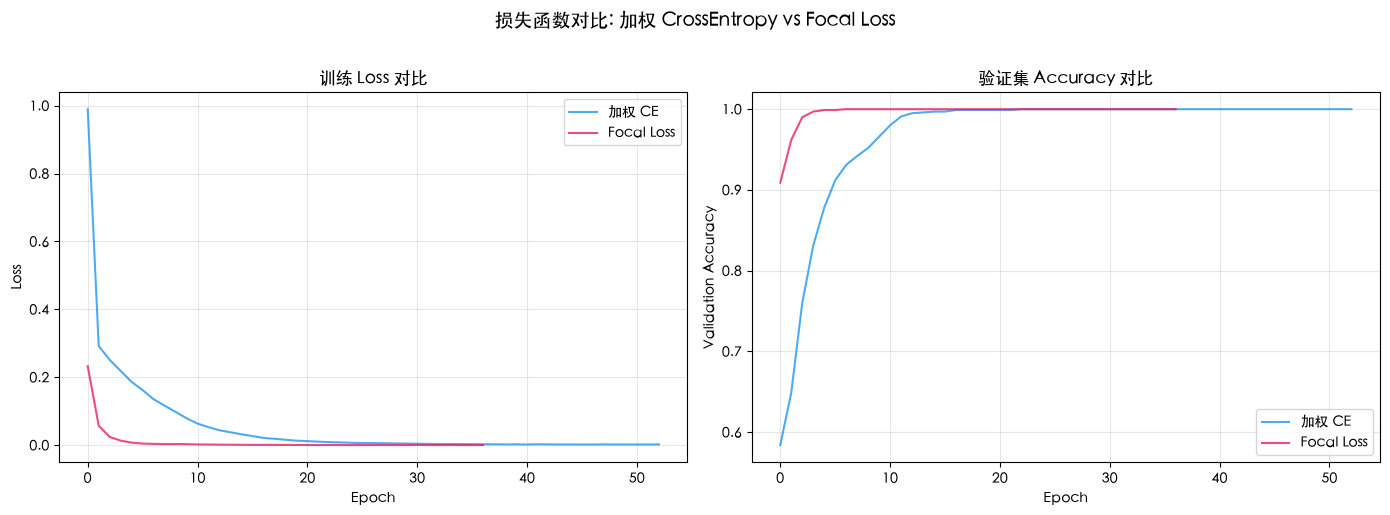

In [22]:
# 绘制训练过程
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss 曲线
axes[0].plot(result1['history']['train_loss'], label='加权 CE', color='#2196F3', alpha=0.8)
axes[0].plot(result2['history']['train_loss'], label='Focal Loss', color='#E91E63', alpha=0.8)
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].set_title('训练 Loss 对比')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Validation Accuracy
axes[1].plot(result1['history']['val_acc'], label='加权 CE', color='#2196F3', alpha=0.8)
axes[1].plot(result2['history']['val_acc'], label='Focal Loss', color='#E91E63', alpha=0.8)
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Validation Accuracy')
axes[1].set_title('验证集 Accuracy 对比')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.suptitle('损失函数对比: 加权 CrossEntropy vs Focal Loss', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

## 关键要点总结

1. **异构图 GNN**能够同时利用多种实体类型和关系类型进行建模
2. **类别不平衡**是风控场景的核心挑战：Focal Loss 和类别加权是有效的应对手段
3. **团伙发现**是 GNN 相比传统方法的核心价值——可以发现整个欺诈团伙而不仅是单个欺诈账户
4. **业务指标**（Precision@K、团伙覆盖率）比纯准确度更能反映模型在风控中的实际价值

> **下一步**：了解模型的可解释性和部署方法，请参考：
> -  — 理解模型为什么做某个判断
> -  — 将模型部署到生产环境